### EDA of the full year 2025

**Objective**: Run the Q1 pipeline (`eda_q1_2025.ipynb`) on the 365 days of 2025, and add the checks that only make sense across quarters.

The Q1 notebook is kept as is. This one writes to `cache/full_2025/` and `figures/full_2025/`, so no Q1 output is overwritten.

#### 1 - Scope and Configuration

The next cell defines a frozen configuration object (`cfg`) holding every project parameter: data paths and period, exposure filters, horizons H, minimum warning times L, critical SMART attributes, cost ratios and the seed. It also creates the cache and figure folders and checks that the daily CSV files exist.

Compared with Q1, only the period and the paths change. The quarter folders are found with a glob (`data_root / data_Q*_<year>`) and the year is read from `start_date`. All other parameters are unchanged, so Q1 and the full year stay comparable. The exposure filters count drive-days and failures, not rates, so they stay as they are.

In [1]:
from pathlib import Path
from dataclasses import dataclass, field
import random
import numpy as np

@dataclass(frozen=True)
class Config:
    # --- Data location and period ---
    data_root: Path = Path("../data")               # contains one folder per quarter: data_Q<n>_<year>/YYYY-MM-DD.csv
    start_date: str = "2025-01-01"
    end_date: str = "2025-12-31"
    cache_dir: Path = Path("cache/full_2025")       # intermediate results (kept apart from the Q1 notebook)
    fig_dir: Path = Path("figures/full_2025")

    # --- Scope ---
    hdd_only: bool = True                           # SSD filter
    min_drive_days_per_model: int = 10_000          # exposure filter for AFR reliability (Annualized Failure Rate)
    min_failures_per_model: int = 5                 # minimum failures to report a model-level rate

    # --- Prediction design ---
    horizons_H: tuple = (7, 14, 30)                 # "fails within H days"
    min_warning_L: tuple = (3, 7, 14)               # minimum actionable lead time (days)
    prefailure_window: int = 60                     # days before failure 

    # --- SMART attributes to focus on ---
    critical_smart: tuple = (5, 187, 188, 197, 198)
    other_smart: tuple = (9, 194)                   # power-on hours, temperature

    # --- Cost scenarios (ratio R/M, replacement vs failure cost) ---
    cost_ratios: tuple = (0.05, 0.2, 0.5)

    # --- Reproducibility ---
    seed: int = 42

    # --- Derived helpers ---
    @property
    def year(self):
        return self.start_date[:4]

    @property
    def data_dirs(self):
        return sorted(self.data_root.glob(f"data_Q*_{self.year}"))

    @property
    def critical_cols_raw(self):
        return [f"smart_{i}_raw" for i in self.critical_smart]

    @property
    def critical_cols_norm(self):
        return [f"smart_{i}_normalized" for i in self.critical_smart]

    @property
    def other_cols_raw(self):
        return [f"smart_{i}_raw" for i in self.other_smart]

cfg = Config()

# --- Setup ---
random.seed(cfg.seed)
np.random.seed(cfg.seed)
cfg.cache_dir.mkdir(parents=True, exist_ok=True)
cfg.fig_dir.mkdir(parents=True, exist_ok=True)

# --- Sanity check: are the input files where we expect them? ---
files = sorted(f for d in cfg.data_dirs for f in d.glob("*.csv"))
assert files, f"No CSV files found in {cfg.data_root.resolve()}"

print(f"Period          : {cfg.start_date} -> {cfg.end_date}")
print(f"Quarter folders : {[d.name for d in cfg.data_dirs]}")
print(f"Daily files     : {len(files)}  ({files[0].name} ... {files[-1].name})")
print(f"Horizons H      : {cfg.horizons_H}")
print(f"Min warning L   : {cfg.min_warning_L}")
print(f"Critical SMART  : {cfg.critical_smart}")
print(f"HDD only        : {cfg.hdd_only}")

Period          : 2025-01-01 -> 2025-12-31
Quarter folders : ['data_Q1_2025', 'data_Q2_2025', 'data_Q3_2025', 'data_Q4_2025']
Daily files     : 365  (2025-01-01.csv ... 2025-12-31.csv)
Horizons H      : (7, 14, 30)
Min warning L   : (3, 7, 14)
Critical SMART  : (5, 187, 188, 197, 198)
HDD only        : True


**Why these SMART attributes?** The five critical attributes (5, 187, 188, 197, 198) were chosen for three reasons:

1. **Close to the failure mechanism.** They count media and read/write errors the drive could not recover from. Attributes 9 (power-on hours) and 194 (temperature) only describe usage or environment, so they are kept as context (`other_smart`).
2. **Supported by prior work.** Pinheiro et al. [1] found that scan errors, reallocations, offline reallocations and probational counts strongly raise failure probability (e.g. 39 times more likely to fail within 60 days after a first scan error), though SMART alone misses a large share of failures. Backblaze uses 5, 187, 188, 197 and 198 as its predictive set [2]. This keeps our results comparable and avoids searching ~100 sparse attributes with very few failures.
3. **Practical.** 5, 197 and 198 are reported by most models (about 97-99% of drive-days), while 187 and 188 are Seagate-only in practice (see part 3.3). All five are counters that stay near 0 on a healthy drive and rise before failure, so trend features are easy to build.

**References**
1. E. Pinheiro, W.-D. Weber and L. A. Barroso, "Failure Trends in a Large Disk Drive Population," in *Proc. 5th USENIX Conf. on File and Storage Technologies (FAST)*, 2007.
2. Backblaze, "Hard Drive SMART Stats," https://www.backblaze.com/blog/hard-drive-smart-stats/

#### 2 - Loading, schema audit and harmonization

##### 2.1 - Loading and schema audit

This cell:
- reads the header of each daily CSV and checks that the schema is the same in all 365 files;
- converts each quarter into its own Parquet file (skipped if it already exists, so an interrupted run resumes; a file is renamed only once complete);
- pins the type of every non-SMART column, so a column cannot be read as a number in one quarter and as text in another;
- reports the size, classifies the columns (identifier, target, static, SMART raw/normalized) and checks that the SMART columns of `cfg` exist;
- compares the dates in the data with the calendar and the files, to detect missing days;
- shows the most common models and a few sample rows.

In [2]:
import re
import duckdb
import pandas as pd
from collections import Counter

con = duckdb.connect()
tmp_dir = cfg.cache_dir / "duckdb_tmp"
tmp_dir.mkdir(exist_ok=True)
con.execute("SET memory_limit = '8GB'")                     # the machine has 13 GB of RAM
con.execute(f"SET temp_directory = '{tmp_dir.as_posix()}'")
parquet_dir = cfg.cache_dir / f"drivestats_{cfg.year}"      # one Parquet file per quarter
parquet_dir.mkdir(exist_ok=True)

# --- 1. Schema consistency across daily files (header only, fast) ---
headers = {f: tuple(pd.read_csv(f, nrows=0).columns) for f in files}
schema_variants = Counter(headers.values())
all_cols = list(dict.fromkeys(c for h in headers.values() for c in h))

print(f"Files: {len(files)} | distinct schemas: {len(schema_variants)} | union columns: {len(all_cols)}")
if len(schema_variants) > 1:
    common = set.intersection(*[set(h) for h in headers.values()])
    print("Columns missing in some files:", sorted(set(all_cols) - common))

# --- 2. Pinned types: SMART columns are DOUBLE, the others are listed one by one ---
STATIC_TYPES = {"date": "DATE", "serial_number": "VARCHAR", "model": "VARCHAR", "capacity_bytes": "BIGINT",
                "failure": "TINYINT", "datacenter": "VARCHAR", "cluster_id": "VARCHAR", "vault_id": "BIGINT",
                "pod_id": "VARCHAR", "pod_slot_num": "VARCHAR", "is_legacy_format": "BOOLEAN"}
types = {c: "DOUBLE" for c in all_cols if c.startswith("smart_")} | STATIC_TYPES
unpinned = [c for c in all_cols if c not in types]
print("Columns without a pinned type (inferred):", unpinned or "none")

# --- 3. Convert the CSVs -> one Parquet file per quarter (skipped if already done) ---
for qdir in cfg.data_dirs:
    out = parquet_dir / f"{qdir.name}.parquet"
    if out.exists():
        continue
    qfiles = [f for f in files if f.parent == qdir]
    file_list = "[" + ",".join(f"'{f.as_posix()}'" for f in qfiles) + "]"
    tmp = out.with_name(out.name + ".part")
    con.execute(f"""
        COPY (
            SELECT * FROM read_csv({file_list}, union_by_name=true, types={types})
            WHERE date BETWEEN DATE '{cfg.start_date}' AND DATE '{cfg.end_date}'
        ) TO '{tmp.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
    tmp.rename(out)
    print(f"{qdir.name}: {len(qfiles)} files -> {out.name} ({out.stat().st_size / 1e9:.2f} GB)")

quarter_files = sorted(parquet_dir.glob("*.parquet"))
con.execute(f"CREATE OR REPLACE VIEW raw AS SELECT * FROM read_parquet('{(parquet_dir / '*.parquet').as_posix()}')")

# --- 4. Basic shape ---
n_rows = con.execute("SELECT COUNT(*) FROM raw").fetchone()[0]
schema = con.execute("DESCRIBE raw").df()[["column_name", "column_type"]]
size_gb = sum(p.stat().st_size for p in quarter_files) / 1e9
print(f"\nRows: {n_rows:,} | Columns: {len(schema)} | Parquet files: {len(quarter_files)} | Parquet size: {size_gb:.2f} GB")

# --- 5. Column classification ---
cols = schema["column_name"].tolist()
target_col  = ["failure"]
id_cols     = [c for c in ["date", "serial_number", "model"] if c in cols]
smart_raw   = [c for c in cols if re.fullmatch(r"smart_\d+_raw", c)]
smart_norm  = [c for c in cols if re.fullmatch(r"smart_\d+_normalized", c)]
static_cols = [c for c in cols if c not in id_cols + target_col + smart_raw + smart_norm]

print(f"\nIdentifiers : {id_cols}")
print(f"Target      : {target_col}")
print(f"Static/other: {static_cols}")
print(f"SMART raw   : {len(smart_raw)} | SMART normalized: {len(smart_norm)}")

# Are the config's critical SMART columns present?
missing = [c for c in cfg.critical_cols_raw + cfg.critical_cols_norm + cfg.other_cols_raw if c not in cols]
print("Missing configured SMART columns:", missing or "none")

# --- 6. Date coverage vs the calendar and the files ---
expected = pd.date_range(cfg.start_date, cfg.end_date)
seen = pd.DatetimeIndex(con.execute("SELECT DISTINCT date FROM raw").df()["date"])
file_dates = pd.to_datetime([f.stem for f in files])
print(f"\nDates: {seen.min().date()} -> {seen.max().date()} | distinct days: {len(seen)} | "
      f"expected: {len(expected)} | files: {len(files)}")
print("Calendar days without data :", [d.date().isoformat() for d in expected.difference(seen)] or "none")
print("Data days without a file   :", [d.date().isoformat() for d in seen.difference(file_dates)] or "none")

# --- 7. Quick look: model names (to design the HDD/SSD filter and manufacturer parsing) ---
models = con.execute("""
    SELECT model, ROUND(MAX(capacity_bytes)/1e12, 1) AS capacity_tb,
           COUNT(DISTINCT serial_number) AS drives
    FROM raw GROUP BY model ORDER BY drives DESC
""").df()
print(f"\nDistinct models: {len(models)}")
display(models.head(20))

# --- 8. Sample rows and dtypes ---
display(con.execute(f"SELECT {', '.join(id_cols + target_col + static_cols + cfg.critical_cols_raw)} "
                    "FROM raw USING SAMPLE 5").df())
display(schema.assign(kind=lambda x: x.column_name.map(
    lambda c: "target" if c in target_col else "id" if c in id_cols
    else "smart_raw" if c in smart_raw else "smart_norm" if c in smart_norm else "static")
).groupby(["kind", "column_type"]).size().rename("n_cols").reset_index())

Files: 365 | distinct schemas: 1 | union columns: 197
Columns without a pinned type (inferred): none

Rows: 117,394,187 | Columns: 197 | Parquet files: 4 | Parquet size: 3.47 GB

Identifiers : ['date', 'serial_number', 'model']
Target      : ['failure']
Static/other: ['capacity_bytes', 'datacenter', 'cluster_id', 'vault_id', 'pod_id', 'pod_slot_num', 'is_legacy_format']
SMART raw   : 93 | SMART normalized: 93
Missing configured SMART columns: none

Dates: 2025-01-01 -> 2025-12-31 | distinct days: 365 | expected: 365 | files: 365
Calendar days without data : none
Data days without a file   : none

Distinct models: 80


,model,capacity_tb,drives
0,WDC WUH722222ALE6L4,22.0,44577
1,TOSHIBA MG08ACA16TA,16.0,40411
2,TOSHIBA MG07ACA14TA,14.0,37705
3,ST16000NM001G,16.0,34563
4,WDC WUH721816ALE6L4,16.0,26493
5,ST12000NM0008,12.0,19145
6,TOSHIBA MG10ACA20TE,20.0,18083
7,HGST HUH721212ALE604,12.0,13656
8,ST8000NM0055,8.0,13533
9,ST12000NM001G,12.0,13347


,date,serial_number,model,failure,capacity_bytes,datacenter,cluster_id,vault_id,pod_id,pod_slot_num,is_legacy_format,smart_5_raw,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw
0,2025-01-01,ZL005DDM,ST12000NM0008,0,12000138625024,sac0,000,1137,02,0008,False,0.0,0.0,0.0,0.0,0.0
1,2025-01-03,ZL2KARXC,ST16000NM001G,0,16000900661248,phx1,040,2017,03,0009,False,0.0,0.0,0.0,0.0,0.0
2,2025-01-03,43S0A0JDFVKG,TOSHIBA MG08ACA16TA,0,16000900661248,phx1,040,2023,00,0055,False,0.0,NaN,NaN,0.0,0.0
3,2025-01-03,ZGG421DA,WDC WUH722222ALE6L4,0,22000969973760,phx1,040,2026,11,0039,False,0.0,NaN,NaN,0.0,0.0
4,2025-01-03,6250A180FVKG,TOSHIBA MG08ACA16TA,0,16000900661248,iad1,050,1000,00,0049,False,0.0,NaN,NaN,0.0,0.0


,kind,column_type,n_cols
0,id,DATE,1
1,id,VARCHAR,2
2,smart_norm,DOUBLE,93
3,smart_raw,DOUBLE,93
4,static,BIGINT,2
5,static,BOOLEAN,1
6,static,VARCHAR,4
7,target,TINYINT,1


##### 2.2 - Harmonization across quarters

Stacking quarters is safe only if each column means the same thing in each. This cell checks, on the data itself: (1) the Parquet schema of each quarter, (2) the volume per quarter, (3) the models missing from some quarters, (4) whether a serial number keeps one capacity all year, (5) missing values of the static columns and the datacenters per quarter, (6) the coverage of the configured SMART attributes per quarter, and (7) whether the Q1 part of the stack reproduces the Q1 notebook. Nothing is modified.

In [3]:
# --- 1. Same Parquet schema (names, order, types) in every quarter? ---
def parquet_schema(p):
    d = con.execute(f"DESCRIBE SELECT * FROM read_parquet('{p.as_posix()}')").df()
    return tuple(zip(d["column_name"], d["column_type"]))

schemas = {p.stem.removeprefix("data_"): parquet_schema(p) for p in quarter_files}
ref_name, ref = next(iter(schemas.items()))
print(f"Parquet schemas identical in all {len(schemas)} quarters: {all(s == ref for s in schemas.values())}")
for q, s in schemas.items():
    if s != ref:
        print(f"  {q} differs from {ref_name}:", sorted(set(s) ^ set(ref)))

# --- 2. Volume per quarter ---
con.execute("CREATE OR REPLACE VIEW rq AS SELECT *, 'Q' || quarter(date) AS q FROM raw")
per_q = con.execute("""
    SELECT q, COUNT(DISTINCT date) AS days, COUNT(*) AS drive_days, COUNT(DISTINCT serial_number) AS drives,
           COUNT(DISTINCT model) AS models, SUM(failure)::INT AS failures
    FROM rq GROUP BY q ORDER BY q
""").df()
per_q["drive_days_per_day"] = (per_q["drive_days"] / per_q["days"]).round(0).astype(int)
per_q["afr_%"] = (per_q["failures"] / per_q["drive_days"] * 365 * 100).round(2)
print("\nVolume per quarter")
display(per_q)

# --- 3. Models that are not present in every quarter ---
mq = (con.execute("SELECT model, q, COUNT(*) AS n FROM rq GROUP BY ALL").df()
      .pivot(index="model", columns="q", values="n").fillna(0).astype(int))
partial = mq[(mq == 0).any(axis=1)]
share = partial.to_numpy().sum() / mq.to_numpy().sum()
print(f"\nModels: {len(mq)} | present in all quarters: {len(mq) - len(partial)} | "
      f"missing from at least one quarter: {len(partial)} ({share:.2%} of drive-days)")
display(partial.assign(total=partial.sum(axis=1)).sort_values("total", ascending=False).head(15))

# --- 4. Does a serial number keep the same capacity all year? ---
cap = con.execute("""
    SELECT COUNT(*) FROM (SELECT serial_number FROM raw GROUP BY serial_number
                          HAVING COUNT(DISTINCT capacity_bytes) > 1)
""").fetchone()[0]
print(f"\nSerial numbers with more than one capacity_bytes value: {cap:,}")

# --- 5. Static columns: share of missing values per quarter, and datacenters present ---
static_nulls = con.execute("SELECT q, " + ", ".join(
    f'ROUND(100.0 * (COUNT(*) - COUNT("{c}")) / COUNT(*), 2) AS "{c}"' for c in static_cols) + " FROM rq GROUP BY q ORDER BY q").df()
print("\nMissing values in the static columns (% of rows)")
display(static_nulls.set_index("q"))
dcs = con.execute("SELECT q, STRING_AGG(DISTINCT COALESCE(datacenter, '<null>'), ', ' ORDER BY COALESCE(datacenter, '<null>')) AS datacenters "
                  "FROM rq GROUP BY q ORDER BY q").df()
print("Datacenters per quarter")
display(dcs.set_index("q"))

# --- 6. Coverage of the configured SMART attributes, per quarter (% of drive-days) ---
focus = cfg.critical_cols_raw + cfg.other_cols_raw
cov_q = con.execute("SELECT q, " + ", ".join(f'ROUND(100.0 * COUNT("{c}") / COUNT(*), 1) AS "{c}"' for c in focus)
                    + " FROM rq GROUP BY q ORDER BY q").df().set_index("q")
print("\nCoverage of the configured SMART attributes per quarter (% of drive-days)")
display(cov_q)

# --- 7. Does the Q1 part of the stack reproduce the Q1 notebook? ---
q1_cache = Path("cache/drivestats_q1_2025.parquet")
if q1_cache.exists():
    q1_old = con.execute(f"SELECT COUNT(*), SUM(failure)::INT, COUNT(DISTINCT serial_number) FROM read_parquet('{q1_cache.as_posix()}')").fetchone()
    q1_new = con.execute("SELECT COUNT(*), SUM(failure)::INT, COUNT(DISTINCT serial_number) FROM rq WHERE q = 'Q1'").fetchone()
    print(f"\nQ1 notebook : rows {q1_old[0]:,} | failures {q1_old[1]:,} | drives {q1_old[2]:,}")
    print(f"Q1 of stack : rows {q1_new[0]:,} | failures {q1_new[1]:,} | drives {q1_new[2]:,}")
    print("Identical   :", q1_old == q1_new)
else:
    print("\nQ1 notebook cache not found: comparison skipped")

Parquet schemas identical in all 4 quarters: True

Volume per quarter


,q,days,drive_days,drives,models,failures,drive_days_per_day,afr_%
0,Q1,90,27799986,318426,76,1067,308889,1.40
1,Q2,91,28808042,322499,75,1061,316572,1.34
2,Q3,92,29844451,332915,77,1254,324396,1.53
3,Q4,92,30941708,341664,78,945,336323,1.11



Models: 80 | present in all quarters: 74 | missing from at least one quarter: 6 (0.40% of drive-days)


q,Q1,Q2,Q3,Q4,total
model,,,,,
TOSHIBA MG11ACA24TE,0,0,24148,349939,374087
WDC WUH722626ALE6L4,0,0,0,91690,91690
ST16000NM000G,0,0,160,1357,1517
HGST HUS726040ALE610,498,0,0,0,498
Samsung SSD 870 EVO 2TB,0,72,92,92,256
ST4000DM000,144,0,0,0,144



Serial numbers with more than one capacity_bytes value: 0

Missing values in the static columns (% of rows)


...

Datacenters per quarter


,datacenters
q,
Q1,"ams5, iad1, phx1, sac0, sac2, yyz1"
Q2,"ams5, iad1, phx1, sac0, sac2, yyz1"
Q3,"ams5, iad1, phx1, sac0, sac2, yyz1"
Q4,"ams5, iad1, phx1, sac0, sac2, yyz1"



Coverage of the configured SMART attributes per quarter (% of drive-days)


,smart_5_raw,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw,smart_9_raw,smart_194_raw
q,,,,,,,
Q1,99.3,35.0,34.8,97.2,99.2,99.9,99.9
Q2,99.3,34.8,34.6,97.3,99.2,99.9,99.9
Q3,99.3,34.6,34.4,97.3,99.2,99.9,99.9
Q4,99.3,33.6,33.5,97.5,99.2,99.9,99.9



Q1 notebook : rows 27,799,986 | failures 1,067 | drives 318,426
Q1 of stack : rows 27,799,986 | failures 1,067 | drives 318,426
Identical   : True


**Takeaways (2.1 and 2.2).**

- **The quarters stack without renaming.** One schema of 197 columns in all 365 files, identical Parquet types in the four quarters. Harmonization was a check, not a transformation. The types stay pinned so a future quarter cannot change them silently.
- **The calendar is complete.** 365 days, 365 files, none missing. The stack has 117,394,187 drive-days, 349,462 drives and 80 models. Its Q1 part matches the Q1 notebook exactly (27,799,986 rows, 1,067 failures, 318,426 drives).
- **The fleet changes slowly.** Drive-days per day grow from about 309k (Q1) to 336k (Q4). 74 models are present all year. The other six hold 0.40% of drive-days, mainly TOSHIBA MG11ACA24TE (from 2025-09-17) and WDC WUH722626ALE6L4 (Q4 only).
- **Identity columns are stable.** No serial number changes capacity, the same six datacenters appear in every quarter, and only `pod_slot_num` has missing values (about 1.3-1.4% per quarter).
- **SMART coverage does not drift.** The only visible move is `smart_187_raw` (35.0% to 33.6%), which follows the Seagate share of the fleet.
- **AFR by quarter: 1.40%, 1.34%, 1.53%, 1.11%.** The low Q4 value is probably an artefact (see 4.6).

#### 3 - Data quality

This part checks the data before any labelling or modelling: (3.1) manufacturer and exposure per model, (3.2) duplicates and key integrity, (3.3) missing SMART values. The cells are those of the Q1 notebook, run on the full year.

##### 3.1 - Drive-days per model and manufacturer

The dataset has no manufacturer column, so it is derived from the model name with ordered regex rules (first match wins). Unmatched models are labelled `Other` and printed.

A drive-day is one row (one drive on one day). The tables give, per model and manufacturer, the drive-days, the distinct drives and the share of exposure. Each model is flagged against `cfg.min_drive_days_per_model`.

In [4]:
# --- Manufacturer from the model name (ordered rules, first match wins) ---
MANUFACTURER_RULES = [
    (r"^(SEAGATE|ST\d)",                         "Seagate"),
    (r"^(HGST|HITACHI|HUH|HMS|HDS)",              "HGST"),
    (r"^(WDC|WD\d|WD |WUH)",                         "Western Digital"),
    (r"^(TOSHIBA|MG\d|MD\d|MN\d|DT\d)",        "Toshiba"),
    (r"^(SAMSUNG|MZ)",                            "Samsung"),
    (r"^(MICRON|MTFD|CRUCIAL|CT\d)",              "Micron/Crucial"),
    (r"^(DELL)",                                  "Dell"),
    (r"^(KINGSTON|SA\d)",                         "Kingston"),
    (r"^(SSDSC|INTEL)",                           "Intel"),
    (r"^(SANDISK|SD\w)",                          "SanDisk"),
]

def manufacturer_of(model):
    name = str(model).strip().upper()
    return next((m for pattern, m in MANUFACTURER_RULES if re.match(pattern, name)), "Other")

# Models are COALESCEd so that a missing model name stays visible instead of being dropped by joins/groupbys
con.execute("CREATE OR REPLACE VIEW dq AS SELECT * REPLACE (COALESCE(model, '<unknown>') AS model) FROM raw")

per_model = con.execute("""
    SELECT model,
           COUNT(*)                          AS drive_days,
           COUNT(DISTINCT serial_number)     AS drives,
           ROUND(MAX(capacity_bytes)/1e12, 1) AS capacity_tb,
           MIN(date)                         AS first_day,
           MAX(date)                         AS last_day
    FROM dq GROUP BY model
""").df()
per_model["manufacturer"] = per_model["model"].map(manufacturer_of)
per_model["share_%"] = (100 * per_model["drive_days"] / per_model["drive_days"].sum()).round(2)
per_model["exposure_ok"] = per_model["drive_days"] >= cfg.min_drive_days_per_model
per_model = per_model.sort_values("drive_days", ascending=False).reset_index(drop=True)

# Make the model -> manufacturer mapping available to SQL for later parts
con.execute("CREATE OR REPLACE TABLE model_info AS SELECT model, manufacturer FROM per_model")

unmapped = per_model.loc[per_model["manufacturer"] == "Other", "model"].tolist()
print(f"Models: {len(per_model)} | unmapped (-> 'Other'): {len(unmapped)}")
if unmapped:
    print("  ", unmapped)

per_manuf = (per_model.groupby("manufacturer")
             .agg(models=("model", "count"), drives=("drives", "sum"), drive_days=("drive_days", "sum"),
                  models_exposure_ok=("exposure_ok", "sum"))
             .assign(**{"share_%": lambda d: (100 * d["drive_days"] / d["drive_days"].sum()).round(2)})
             .sort_values("drive_days", ascending=False))
# drives is summed over models: a serial seen under two models would count twice (checked in 3.2)

ok = per_model["exposure_ok"]
print(f"\nTotal drive-days: {per_model['drive_days'].sum():,} | "
      f"models >= {cfg.min_drive_days_per_model:,} drive-days: {ok.sum()}/{len(per_model)} "
      f"({per_model.loc[ok, 'drive_days'].sum() / per_model['drive_days'].sum():.2%} of drive-days)")

print("\nPer manufacturer")
display(per_manuf)
print("Per model (top 25 by drive-days)")
display(per_model.head(25))
print("Models below the exposure filter (bottom 10)")
display(per_model.loc[~ok].tail(10))

Models: 80 | unmapped (-> 'Other'): 0

Total drive-days: 117,394,187 | models >= 10,000 drive-days: 56/80 (99.95% of drive-days)

Per manufacturer


,models,drives,drive_days,models_exposure_ok,share_%
manufacturer,,,,,
Seagate,37,117068,40824991,25,34.78
Toshiba,11,114251,38092728,11,32.45
Western Digital,11,84814,27758805,10,23.65
HGST,10,32068,10266634,7,8.75
Micron/Crucial,4,820,291346,2,0.25
Dell,1,433,157243,1,0.13
Samsung,4,6,1796,0,0.00
Intel,2,2,644,0,0.00


Per model (top 25 by drive-days)


,model,drive_days,drives,capacity_tb,first_day,last_day,manufacturer,share_%,exposure_ok
0,TOSHIBA MG08ACA16TA,14623715,40411,16.0,2025-01-01,2025-12-31,Toshiba,12.46,True
1,TOSHIBA MG07ACA14TA,13654728,37705,14.0,2025-01-01,2025-12-31,Toshiba,11.63,True
2,WDC WUH722222ALE6L4,13612879,44577,22.0,2025-01-01,2025-12-31,Western Digital,11.60,True
3,ST16000NM001G,12381689,34563,16.0,2025-01-01,2025-12-31,Seagate,10.55,True
4,WDC WUH721816ALE6L4,9615277,26493,16.0,2025-01-01,2025-12-31,Western Digital,8.19,True
5,ST12000NM0008,6877112,19145,12.0,2025-01-01,2025-12-31,Seagate,5.86,True
6,TOSHIBA MG10ACA20TE,4909379,18083,20.0,2025-01-01,2025-12-31,Toshiba,4.18,True
7,ST8000NM0055,4870236,13533,8.0,2025-01-01,2025-12-31,Seagate,4.15,True
8,HGST HUH721212ALE604,4853717,13656,12.0,2025-01-01,2025-12-31,HGST,4.13,True
9,ST12000NM001G,4817914,13347,12.0,2025-01-01,2025-12-31,Seagate,4.10,True


Models below the exposure filter (bottom 10)


,model,drive_days,drives,capacity_tb,first_day,last_day,manufacturer,share_%,exposure_ok
70,MTFDDAV480TCB,728,2,0.5,2025-01-01,2025-12-31,Micron/Crucial,0.0,False
71,Samsung SSD 850 EVO 1TB,621,2,1.0,2025-01-01,2025-12-31,Samsung,0.0,False
72,Samsung SSD 860 PRO 2TB,620,2,2.0,2025-01-01,2025-12-31,Samsung,0.0,False
73,HGST HUS726040ALE610,498,6,4.0,2025-01-01,2025-03-29,HGST,0.0,False
74,ST1000LM024 HN,365,1,1.0,2025-01-01,2025-12-31,Seagate,0.0,False
75,SSDSCKKB240GZR,365,1,0.2,2025-01-01,2025-12-31,Intel,0.0,False
76,Samsung SSD 850 PRO 1TB,299,1,1.0,2025-03-08,2025-12-31,Samsung,0.0,False
77,SSDSCKKB480G8R,279,1,0.5,2025-03-28,2025-12-31,Intel,0.0,False
78,Samsung SSD 870 EVO 2TB,256,1,2.0,2025-04-20,2025-12-31,Samsung,0.0,False
79,ST4000DM000,144,2,4.0,2025-01-01,2025-03-13,Seagate,0.0,False


##### 3.2 - Duplicates and key integrity

A row should be unique on `(date, serial_number)`. This cell counts missing values in the key and target columns, then duplicated keys (exact copies or conflicting rows), and serial numbers that appear under more than one model. Nothing is modified.

In [5]:
# --- 1. Missing values in key / target columns ---
key_cols = ["date", "serial_number", "model", "capacity_bytes", "failure"]
nulls = con.execute("SELECT " + ", ".join(f'COUNT(*) - COUNT("{c}") AS "{c}"' for c in key_cols) + " FROM raw").df()
print("Null counts in key/target columns:")
display(nulls)

# --- 2. Duplicated (date, serial_number) keys ---
dup = con.execute("""
    SELECT COUNT(*) AS dup_keys, COALESCE(SUM(n - 1), 0) AS extra_rows
    FROM (SELECT COUNT(*) AS n FROM raw GROUP BY date, serial_number HAVING COUNT(*) > 1)
""").fetchone()
print(f"\nDuplicated (date, serial_number) keys: {dup[0]:,} | extra rows: {int(dup[1]):,} "
      f"({int(dup[1]) / n_rows:.6%} of rows)")

if dup[0] > 0:
    # Exact copies vs conflicting rows: DISTINCT over the full row, restricted to duplicated keys
    exact = con.execute("""
        WITH dup_keys AS (SELECT date, serial_number FROM raw GROUP BY date, serial_number HAVING COUNT(*) > 1)
        SELECT COUNT(*) FROM (SELECT DISTINCT r.* FROM raw r
                              SEMI JOIN dup_keys d ON r.date = d.date AND r.serial_number = d.serial_number)
    """).fetchone()[0]
    conflicting = exact - dup[0]
    print(f"Distinct rows among duplicated keys: {exact:,} -> exact copies: {dup[1] - conflicting:,.0f}, "
          f"keys with conflicting content: {conflicting:,}")
    display(con.execute("""
        SELECT date, serial_number, model, COUNT(*) AS n, SUM(failure) AS failures
        FROM dq GROUP BY ALL HAVING COUNT(*) > 1 ORDER BY n DESC, date LIMIT 10
    """).df())

# --- 3. Serial numbers shared by several models ---
multi = con.execute("""
    SELECT serial_number, COUNT(DISTINCT model) AS n_models, STRING_AGG(DISTINCT model, ' | ') AS models
    FROM dq GROUP BY serial_number HAVING COUNT(DISTINCT model) > 1
""").df()
print(f"\nSerial numbers seen under more than one model: {len(multi):,}")
if len(multi):
    display(multi.head(10))

Null counts in key/target columns:


,date,serial_number,model,capacity_bytes,failure
0,0,0,0,0,0



Duplicated (date, serial_number) keys: 0 | extra rows: 0 (0.000000% of rows)

Serial numbers seen under more than one model: 0


##### 3.3 - Missing SMART values

Most missing SMART values mean "this model does not report this attribute", not a collection error. This cell measures it in one scan: for each model, the share of drive-days where each `smart_*_raw` attribute is non-null (its coverage). Coverage per manufacturer and overall is rebuilt from the per-model counts, so it is weighted by drive-days.

The attribute list comes from the Parquet schema, so new attributes are picked up automatically. The per-model table is saved to `cfg.cache_dir`. Only raw columns are audited.

In [6]:
# --- 1. One scan: non-null counts per model and per raw SMART attribute ---
count_exprs = ", ".join(f'COUNT("{c}") AS "{c}"' for c in smart_raw)
nn = con.execute(f"SELECT model, COUNT(*) AS n_rows, {count_exprs} FROM dq GROUP BY model").df()
nn["manufacturer"] = nn["model"].map(manufacturer_of)

def coverage(counts):
    """Share of drive-days with a non-null value, from summed non-null counts (drive-day weighted)."""
    return counts[smart_raw].sum() / counts["n_rows"].sum()

cov_model = nn.set_index("model")[smart_raw].div(nn.set_index("model")["n_rows"], axis=0)
cov_manuf = pd.DataFrame({m: coverage(g) for m, g in nn.groupby("manufacturer")}).T
cov_all   = coverage(nn)
cov_model.to_csv(cfg.cache_dir / "smart_raw_coverage_by_model.csv")

# --- 2. Overall picture: how many attributes are usable? ---
bins = pd.cut(cov_all, [-1e-9, 0, 0.05, 0.5, 0.95, 1.0], labels=["never reported", "(0, 5%]", "(5%, 50%]", "(50%, 95%]", "> 95%"])
print(f"SMART raw attributes: {len(smart_raw)}")
display(bins.value_counts().sort_index().rename("n_attributes").to_frame())

# --- 3. Configured attributes (critical + others): overall and per manufacturer ---
focus = cfg.critical_cols_raw + cfg.other_cols_raw
cov_focus = cov_manuf[focus].copy()
cov_focus.loc["ALL"] = cov_all[focus]
print("Coverage of the configured SMART attributes (share of drive-days, by manufacturer)")
display((100 * cov_focus).round(1))

# --- 4. Models that do not report the critical attributes (weighted by their exposure) ---
crit = cfg.critical_cols_raw
exposure = nn.set_index("model")["n_rows"]
missing_crit = (cov_model[crit] < 0.5).rename(columns=lambda c: c.replace("smart_", "").replace("_raw", ""))
lack = missing_crit.any(axis=1)
print(f"Models with < 50% coverage on at least one critical attribute {cfg.critical_smart}: "
      f"{lack.sum()}/{len(cov_model)} models, {exposure[lack].sum() / exposure.sum():.2%} of drive-days")
display(pd.concat([nn.set_index("model")[["manufacturer", "n_rows"]], (100 * cov_model[crit]).round(1)], axis=1)
        .loc[lack].sort_values("n_rows", ascending=False).head(15))

# --- 5. Attributes with the best coverage overall ---
print("Top 15 attributes by overall coverage")
display((100 * cov_all.sort_values(ascending=False).head(15)).round(1).rename("coverage_%").to_frame())

SMART raw attributes: 93


,n_attributes
never reported,10
"(0, 5%]",44
"(5%, 50%]",21
"(50%, 95%]",4
> 95%,14


Coverage of the configured SMART attributes (share of drive-days, by manufacturer)


,smart_5_raw,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw,smart_9_raw,smart_194_raw
Dell,0.0,0.0,0.0,0.0,0.0,0.0,0.0
HGST,100.0,0.0,0.0,100.0,100.0,100.0,100.0
Intel,100.0,0.0,0.0,100.0,100.0,100.0,100.0
Micron/Crucial,100.0,89.0,0.4,89.0,100.0,100.0,100.0
Samsung,100.0,100.0,0.0,0.0,0.0,100.0,0.0
Seagate,98.4,98.3,98.3,98.4,98.4,100.0,100.0
Toshiba,100.0,0.0,0.0,94.3,100.0,100.0,100.0
Western Digital,100.0,0.4,0.6,99.6,99.6,100.0,100.0
ALL,99.3,34.5,34.3,97.3,99.2,99.9,99.9


Models with < 50% coverage on at least one critical attribute (5, 187, 188, 197, 198): 52/80 models, 65.82% of drive-days


,manufacturer,n_rows,smart_5_raw,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw
model,,,,,,,
TOSHIBA MG08ACA16TA,Toshiba,14623715,100.0,0.0,0.0,100.0,100.0
TOSHIBA MG07ACA14TA,Toshiba,13654728,100.0,0.0,0.0,100.0,100.0
WDC WUH722222ALE6L4,Western Digital,13612879,100.0,0.0,0.0,100.0,100.0
WDC WUH721816ALE6L4,Western Digital,9615277,100.0,0.0,0.0,100.0,100.0
TOSHIBA MG10ACA20TE,Toshiba,4909379,100.0,0.0,0.0,100.0,100.0
HGST HUH721212ALE604,HGST,4853717,100.0,0.0,0.0,100.0,100.0
HGST HUH721212ALN604,HGST,3628418,100.0,0.0,0.0,100.0,100.0
WDC WUH721414ALE6L4,Western Digital,3141290,100.0,0.0,0.0,100.0,100.0
TOSHIBA MG08ACA16TE,Toshiba,2188375,100.0,0.0,0.0,100.0,100.0


Top 15 attributes by overall coverage


,coverage_%
smart_9_raw,99.9
smart_12_raw,99.9
smart_194_raw,99.9
smart_1_raw,99.8
smart_192_raw,99.5
smart_5_raw,99.3
smart_199_raw,99.3
smart_198_raw,99.2
smart_3_raw,98.9
smart_7_raw,98.9


**Takeaways (part 3).**

- **The keys are clean.** No missing key or target value, no duplicated `(date, serial_number)`, no serial number under two models.
- **Exposure is concentrated.** 56 of 80 models pass the 10,000 drive-day filter and hold 99.95% of drive-days. Every model maps to a manufacturer. Seagate has 34.8% of drive-days, Toshiba 32.5%, Western Digital 23.7%, HGST 8.8%.
- **SMART availability follows the manufacturer.** Of 93 raw attributes, 14 are reported on over 95% of drive-days and 10 never. Attributes 5, 197 and 198 are at 97-99%. 187 and 188 are at about 34% because only Seagate HDDs report them (98% of Seagate drive-days); the few other reporters are SSDs. 52 of 80 models (65.8% of drive-days) are below 50% on at least one critical attribute. As in Q1, we keep all models and revisit only if the evaluation is poor on them. TOSHIBA MG08ACA16TEY and one Seagate SSD do not report 197.

#### 4 - Failure distribution

This part describes where the failures are: how rare they are, and how the rate varies by model, manufacturer, capacity, datacenter and time. It is descriptive only.

The failure rate is the annualized failure rate, AFR = failures / drive-days x 365. Failures are rare, so every bar carries an exact 95% Poisson interval. Groups below the exposure filters of `cfg` are not drawn, but no row is removed.

The dashed "fleet AFR" line is the pooled AFR of all drives (total failures / total drive-days x 365). It is drive-day weighted, not the mean of the bars, and includes the models that are not drawn.

##### 4.1 - Overall counts, AFR and label consistency

This cell gives drive-days, drives, failures, the AFR against the proposal figures (full year 2025), and the number of positive drive-days for each horizon H (drive-days within H days before a failure).

It also checks the `failure` label (one flagged row per failed drive, none after it) and counts the drives that vanish before the end of the period without a failure flag. Nothing is modified.

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import chi2

PROPOSAL = {"drive_days": 115.6e6, "failures": 4317, "afr_%": 1.36}   # full year 2025, from the project proposal

# --- 1. Overall counts and AFR ---
drive_days, drives, failures = con.execute(
    "SELECT COUNT(*), COUNT(DISTINCT serial_number), SUM(failure)::INT FROM dq").fetchone()
afr_all = failures / drive_days * 365 * 100
print(f"Drive-days: {drive_days:,} | drives: {drives:,} | failures: {failures:,} "
      f"(1 failure per {drive_days / failures:,.0f} drive-days)")
print(f"AFR: {afr_all:.2f}% | proposal (full 2025): {PROPOSAL['afr_%']:.2f}% "
      f"({PROPOSAL['failures']:,} failures over {PROPOSAL['drive_days'] / 1e6:.1f}M drive-days)")

# --- 2. Class imbalance per horizon: drive-days within H days before a failure ---
for H in cfg.horizons_H:
    pos = con.execute(f"""
        WITH f AS (SELECT serial_number, date AS fail_day FROM dq WHERE failure = 1)
        SELECT COUNT(*) FROM dq JOIN f USING (serial_number)
        WHERE dq.date >= f.fail_day - {H} AND dq.date < f.fail_day
    """).fetchone()[0]
    print(f"H = {H:>2} days: {pos:,} positive drive-days ({pos / drive_days:.3%}, 1 in {drive_days / pos:,.0f})")

# --- 3. Label consistency and censored drives ---
multi_flag, after_failure, vanished = con.execute(f"""
    WITH d AS (SELECT serial_number, SUM(failure) AS n_fail, MAX(date) AS last_day,
                      MAX(CASE WHEN failure = 1 THEN date END) AS fail_day
               FROM dq GROUP BY serial_number)
    SELECT COUNT(*) FILTER (WHERE n_fail > 1),
           COUNT(*) FILTER (WHERE n_fail = 1 AND fail_day < last_day),
           COUNT(*) FILTER (WHERE n_fail = 0 AND last_day < DATE '{cfg.end_date}')
    FROM d
""").fetchone()
print(f"\nDrives flagged more than once: {multi_flag} | drives with rows after their failure: {after_failure}")
print(f"Drives that vanish before {cfg.end_date} without a failure flag (censored): {vanished:,} "
      f"({vanished / drives:.2%} of drives)")

Drive-days: 117,394,187 | drives: 349,462 | failures: 4,327 (1 failure per 27,131 drive-days)
AFR: 1.35% | proposal (full 2025): 1.36% (4,317 failures over 115.6M drive-days)
H =  7 days: 26,727 positive drive-days (0.023%, 1 in 4,392)
H = 14 days: 54,012 positive drive-days (0.046%, 1 in 2,173)
H = 30 days: 115,698 positive drive-days (0.099%, 1 in 1,015)

Drives flagged more than once: 17 | drives with rows after their failure: 17
Drives that vanish before 2025-12-31 without a failure flag (censored): 6,354 (1.82% of drives)


##### 4.2 - Failure rate by model and manufacturer

The first chart shows the AFR per model with its 95% interval, coloured by manufacturer. Only models with at least `cfg.min_drive_days_per_model` drive-days and `cfg.min_failures_per_model` failures are drawn, because the rate of a model with a few failures is mostly noise. The second chart shows the AFR by manufacturer. The number next to each bar is its failure count.

The helpers defined here (Poisson interval, AFR table, plot style) are reused by the next steps. The numbers behind each chart are saved to `cfg.cache_dir`.

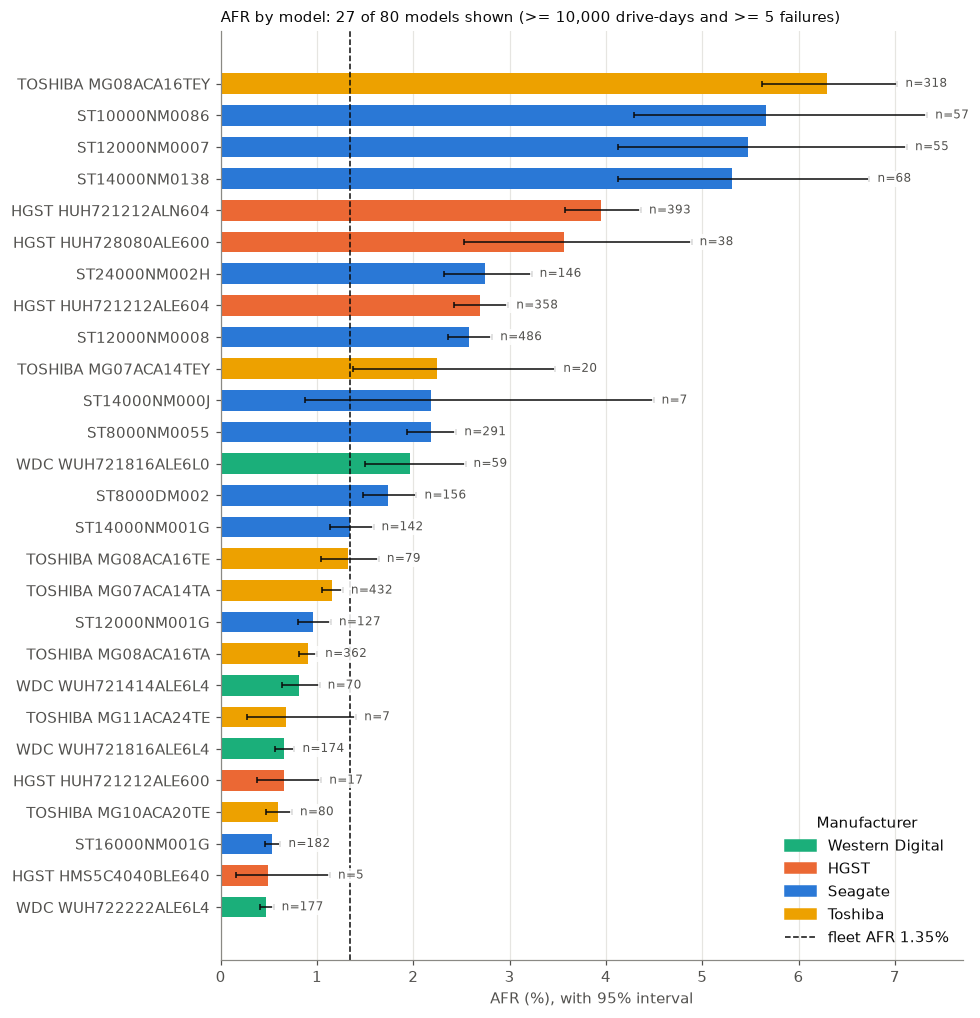

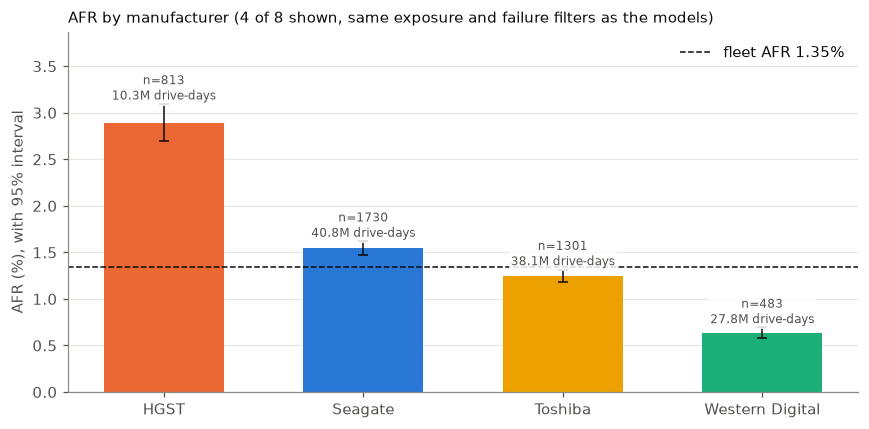

In [8]:
# --- Helpers shared by 4.2 -> 4.5 ---
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10, "figure.dpi": 110,
})
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
MANUF_COLORS = {"Seagate": "#2a78d6", "HGST": "#eb6834", "Western Digital": "#1baf7a", "Toshiba": "#eda100",
                "Samsung": "#e87ba4", "Micron/Crucial": "#008300", "Dell": "#6250d6"}   # fixed order, one colour per manufacturer
OTHER_COLOR = "#8a8984"

def poisson_ci(k, alpha=0.05):
    """Exact (Garwood) confidence interval for a Poisson count k."""
    lo = chi2.ppf(alpha / 2, 2 * k) / 2 if k > 0 else 0.0
    hi = chi2.ppf(1 - alpha / 2, 2 * k + 2) / 2
    return lo, hi

def afr_by(group_sql, join=""):
    """Drive-days, drives, failures, AFR (%) and its 95% interval per group."""
    df = con.execute(f"""
        SELECT {group_sql} AS grp, COUNT(*) AS drive_days, COUNT(DISTINCT serial_number) AS drives,
               SUM(failure)::INT AS failures
        FROM dq {join} GROUP BY 1
    """).df()
    ci = df["failures"].map(poisson_ci)
    scale = 365 * 100 / df["drive_days"]
    df["afr"] = df["failures"] * scale
    df["afr_lo"] = ci.str[0] * scale
    df["afr_hi"] = ci.str[1] * scale
    return df

def yerr(df):
    return [df["afr"] - df["afr_lo"], df["afr_hi"] - df["afr"]]

def drawn(df):
    """Groups with enough exposure and failures for a rate to be drawn (same rule as for the models)."""
    return df[(df["drive_days"] >= cfg.min_drive_days_per_model) & (df["failures"] >= cfg.min_failures_per_model)]

LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=1.2, alpha=0.85)

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(cfg.fig_dir / f"{name}.png", dpi=150)
    plt.show()

# --- 1. AFR per model, coloured by manufacturer ---
by_model = afr_by("model")
by_model["manufacturer"] = by_model["grp"].map(manufacturer_of)
by_model["capacity_tb"] = by_model["grp"].map(per_model.set_index("model")["capacity_tb"])
shown = ((by_model["drive_days"] >= cfg.min_drive_days_per_model)
         & (by_model["failures"] >= cfg.min_failures_per_model))
by_model.to_csv(cfg.cache_dir / "afr_by_model.csv", index=False)
m = by_model[shown].sort_values("afr").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 0.28 * len(m) + 1.8))
ax.barh(m["grp"], m["afr"], xerr=yerr(m), color=m["manufacturer"].map(MANUF_COLORS).fillna(OTHER_COLOR),
        ecolor=INK, error_kw={"elinewidth": 1, "capsize": 2}, height=0.65)
fleet = ax.axvline(afr_all, color=INK, ls="--", lw=1)
for y, (hi, k) in enumerate(zip(m["afr_hi"], m["failures"])):
    ax.text(hi, y, f"  n={k}", va="center", fontsize=8, color=MUTED, bbox=LABEL_BOX)
ax.set_xlabel("AFR (%), with 95% interval")
ax.set_title(f"AFR by model: {shown.sum()} of {len(by_model)} models shown "
             f"(>= {cfg.min_drive_days_per_model:,} drive-days and >= {cfg.min_failures_per_model} failures)",
             loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=MANUF_COLORS.get(k, OTHER_COLOR)) for k in m["manufacturer"].unique()]
ax.legend(handles + [fleet], list(m["manufacturer"].unique()) + [f"fleet AFR {afr_all:.2f}%"],
          loc="lower right", frameon=False, title="Manufacturer")
finish(fig, "afr_by_model")

# --- 2. AFR per manufacturer ---
by_manuf = afr_by("manufacturer", "JOIN model_info USING (model)")
by_manuf.to_csv(cfg.cache_dir / "afr_by_manufacturer.csv", index=False)
mm = drawn(by_manuf).sort_values("afr", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(mm["grp"], mm["afr"], yerr=yerr(mm), color=mm["grp"].map(MANUF_COLORS).fillna(OTHER_COLOR),
       ecolor=INK, error_kw={"elinewidth": 1, "capsize": 3}, width=0.6)
ax.axhline(afr_all, color=INK, ls="--", lw=1, label=f"fleet AFR {afr_all:.2f}%")
for x, (hi, k, dd) in enumerate(zip(mm["afr_hi"], mm["failures"], mm["drive_days"])):
    ax.text(x, hi, f"n={k}\n{dd / 1e6:.1f}M drive-days", ha="center", va="bottom", fontsize=8, color=MUTED, bbox=LABEL_BOX)
ax.legend(frameon=False, loc="upper right")
ax.set_ylabel("AFR (%), with 95% interval")
ax.set_ylim(0, mm["afr_hi"].max() * 1.25)
ax.set_title(f"AFR by manufacturer ({len(mm)} of {len(by_manuf)} shown, same exposure and failure filters as the models)",
             loc="left", fontsize=10)
ax.grid(axis="x", visible=False)
finish(fig, "afr_by_manufacturer")

##### 4.3 - Failure rate by capacity

Capacity is rounded to the nearest TB. A capacity effect can be a model effect, since each capacity is made of a few models. The first chart shows the AFR by capacity. The second shows the same models as points (AFR against capacity, coloured by manufacturer) to see whether the pattern holds inside each manufacturer.

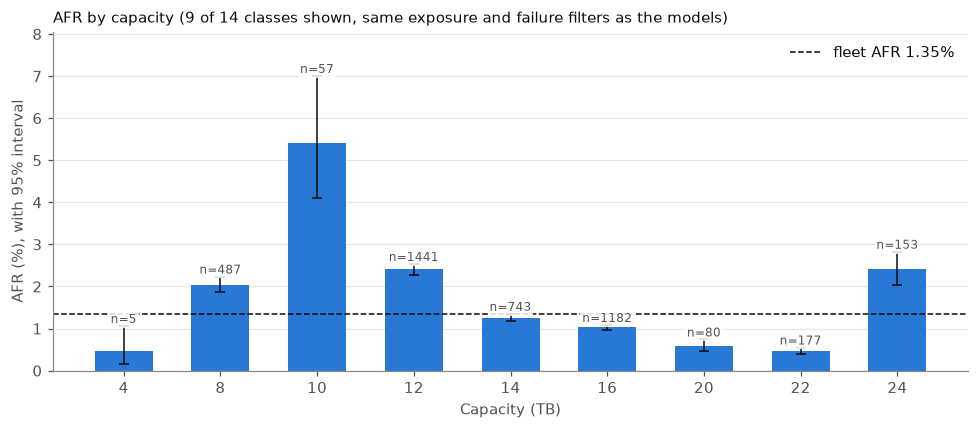

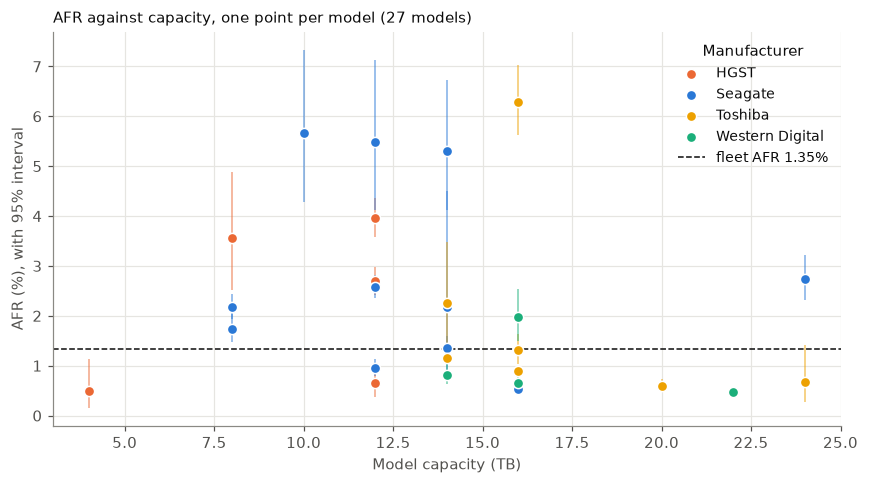

In [9]:
# --- 1. AFR per capacity class ---
by_cap = afr_by("ROUND(capacity_bytes / 1e12)::INT")
by_cap.to_csv(cfg.cache_dir / "afr_by_capacity.csv", index=False)
cc = drawn(by_cap).sort_values("grp").reset_index(drop=True)
cap_labels = ["< 0.5" if g == 0 else str(g) for g in cc["grp"]]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(cap_labels, cc["afr"], yerr=yerr(cc), color=BLUE, ecolor=INK,
       error_kw={"elinewidth": 1, "capsize": 3}, width=0.6)
ax.axhline(afr_all, color=INK, ls="--", lw=1, label=f"fleet AFR {afr_all:.2f}%")
for x, (hi, k) in enumerate(zip(cc["afr_hi"], cc["failures"])):
    ax.text(x, hi, f"n={k}", ha="center", va="bottom", fontsize=8, color=MUTED, bbox=LABEL_BOX)
ax.legend(frameon=False, loc="upper right")
ax.set_xlabel("Capacity (TB)")
ax.set_ylabel("AFR (%), with 95% interval")
ax.set_ylim(0, cc["afr_hi"].max() * 1.15)
ax.set_title(f"AFR by capacity ({len(cc)} of {len(by_cap)} classes shown, same exposure and failure filters as the models)",
             loc="left", fontsize=10)
ax.grid(axis="x", visible=False)
finish(fig, "afr_by_capacity")

# --- 2. Same models as points: is the capacity effect a manufacturer effect? ---
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, g in m.groupby("manufacturer"):
    c = MANUF_COLORS.get(name, OTHER_COLOR)
    ax.errorbar(g["capacity_tb"], g["afr"], yerr=yerr(g), fmt="none", ecolor=c, elinewidth=1, alpha=0.6)
    ax.scatter(g["capacity_tb"], g["afr"], s=45, color=c, edgecolor="white", linewidth=1, zorder=3, label=name)
ax.axhline(afr_all, color=INK, ls="--", lw=1, label=f"fleet AFR {afr_all:.2f}%")
ax.set_xlabel("Model capacity (TB)")
ax.set_ylabel("AFR (%), with 95% interval")
ax.set_title(f"AFR against capacity, one point per model ({len(m)} models)", loc="left", fontsize=10)
ax.legend(frameon=False, title="Manufacturer", fontsize=9)
finish(fig, "afr_vs_capacity_by_model")

##### 4.4 - Failure rate by datacenter

Same chart as for capacity, by `datacenter`. Datacenters do not host the same models, so differences are descriptive and not a datacenter effect. The second chart shows each datacenter's share of drive-days by manufacturer, to make the model mix visible.

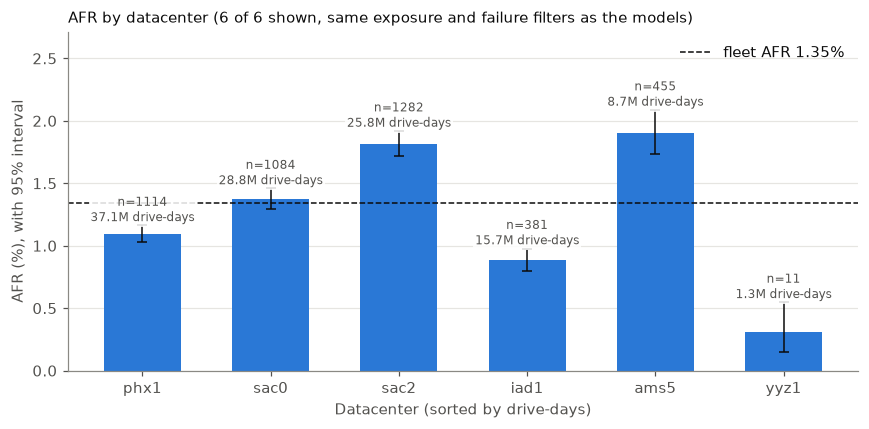

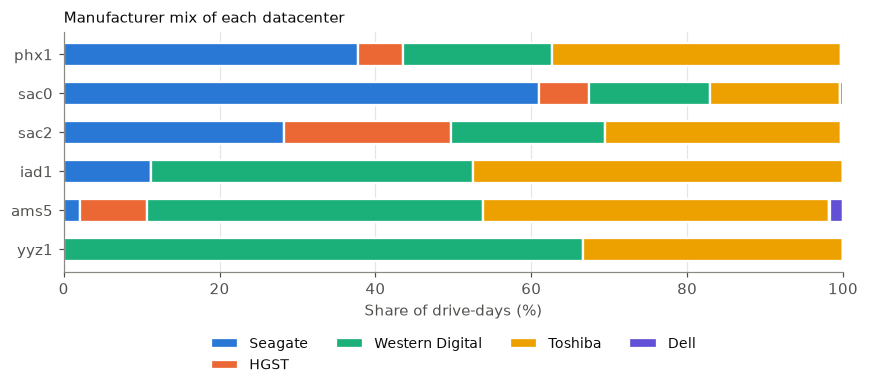

In [10]:
# --- 1. AFR per datacenter ---
by_dc = afr_by("COALESCE(datacenter, '<unknown>')")
by_dc.to_csv(cfg.cache_dir / "afr_by_datacenter.csv", index=False)
dc = drawn(by_dc).sort_values("drive_days", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dc["grp"], dc["afr"], yerr=yerr(dc), color=BLUE, ecolor=INK,
       error_kw={"elinewidth": 1, "capsize": 3}, width=0.6)
ax.axhline(afr_all, color=INK, ls="--", lw=1, label=f"fleet AFR {afr_all:.2f}%")
for x, (hi, k, d) in enumerate(zip(dc["afr_hi"], dc["failures"], dc["drive_days"])):
    ax.text(x, hi, f"n={k}\n{d / 1e6:.1f}M drive-days", ha="center", va="bottom", fontsize=8, color=MUTED, bbox=LABEL_BOX)
ax.legend(frameon=False, loc="upper right")
ax.set_xlabel("Datacenter (sorted by drive-days)")
ax.set_ylabel("AFR (%), with 95% interval")
ax.set_ylim(0, dc["afr_hi"].max() * 1.3)
ax.set_title(f"AFR by datacenter ({len(dc)} of {len(by_dc)} shown, same exposure and failure filters as the models)",
             loc="left", fontsize=10)
ax.grid(axis="x", visible=False)
finish(fig, "afr_by_datacenter")

# --- 2. Model mix of each datacenter (share of drive-days by manufacturer) ---
mix = con.execute("""
    SELECT COALESCE(datacenter, '<unknown>') AS dc, manufacturer, COUNT(*) AS drive_days
    FROM dq JOIN model_info USING (model) GROUP BY ALL
""").df().pivot(index="dc", columns="manufacturer", values="drive_days").fillna(0)
mix = mix.loc[dc["grp"]]
mix = mix.div(mix.sum(axis=1), axis=0) * 100
order = [c for c in MANUF_COLORS if c in mix.columns] + [c for c in mix.columns if c not in MANUF_COLORS]
legend_names = [c for c in order if mix[c].max() >= 0.5]   # legend: manufacturers with >= 0.5% in at least one datacenter

fig, ax = plt.subplots(figsize=(8, 3.8))
left = np.zeros(len(mix))
for name in order:
    ax.barh(mix.index, mix[name], left=left, color=MANUF_COLORS.get(name, OTHER_COLOR), label=name,
            height=0.6, edgecolor="white", linewidth=1.5)
    left += mix[name].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of drive-days (%)")
ax.set_title("Manufacturer mix of each datacenter", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
h, l = ax.get_legend_handles_labels()
keep = [i for i, name in enumerate(l) if name in legend_names]
ax.legend([h[i] for i in keep], [l[i] for i in keep], frameon=False, ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.22), fontsize=9)
finish(fig, "manufacturer_mix_by_datacenter")

##### 4.5 - Failures over time

Failures per day over the year, with a 7-day mean and the period mean as a dashed line. It shows whether failures are evenly spread or come in bursts.

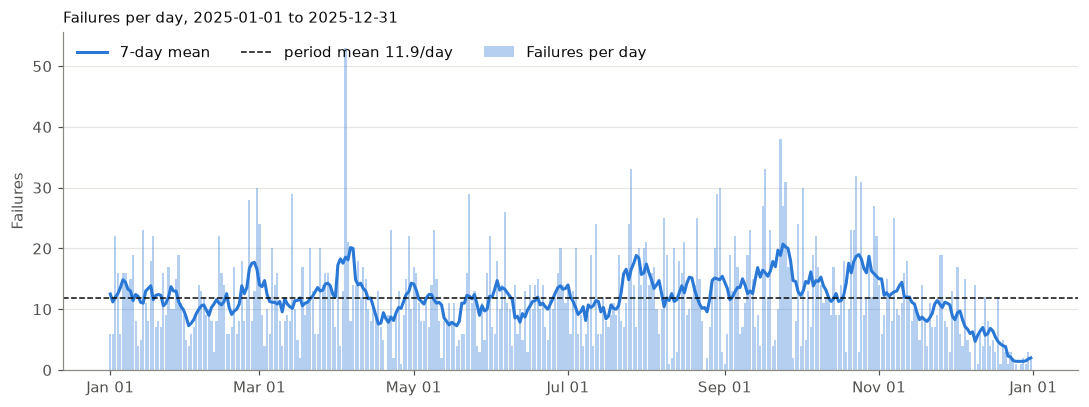

In [11]:
daily = con.execute("SELECT date, SUM(failure)::INT AS failures, COUNT(*) AS drive_days FROM dq GROUP BY date ORDER BY date").df()
daily["date"] = pd.to_datetime(daily["date"])
daily["mean_7d"] = daily["failures"].rolling(7, center=True, min_periods=4).mean()
daily.to_csv(cfg.cache_dir / "failures_by_day.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(daily["date"], daily["failures"], color=BLUE, alpha=0.35, width=0.85, label="Failures per day")
ax.plot(daily["date"], daily["mean_7d"], color=BLUE, lw=2, label="7-day mean")
ax.axhline(daily["failures"].mean(), color=INK, ls="--", lw=1, label=f"period mean {daily['failures'].mean():.1f}/day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylabel("Failures")
ax.set_title(f"Failures per day, {cfg.start_date} to {cfg.end_date}", loc="left", fontsize=10)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left", ncol=3)
finish(fig, "failures_per_day")

##### 4.6 - Takeaways

- **The full year matches the proposal.** 4,327 failure flags over 117.4M drive-days give an AFR of 1.35%, against 4,317 failures, 115.6M drive-days and 1.36% in the proposal. The 1.8M extra drive-days are mostly SSD-like models (about 1.5M by a rough check on name and capacity). `hdd_only` is not applied yet, so SSDs are still in every table; the filter will be applied when the labels are built.
- **Failures are very rare.** 1 drive-day in about 27,000. Drive-days within H days before a failure: 1 in 4,392 (H = 7), 1 in 2,173 (H = 14), 1 in 1,015 (H = 30). Accuracy cannot be used as a metric.
- **The label is less clean than in Q1.** 17 drives are flagged twice and 17 more have rows after their flag, so 4,327 flags belong to 4,310 drives. These 34 drives disappear and come back, mostly TOSHIBA MG08ACA16TEY and WDC WUH721816ALE6L0. Eight of them failed on 25-27 September and again on 6-7 October. They may be drives returned to service after a repair, but this is not checked. The labels will have to cut each drive into episodes ending at a flag.
- **The manufacturer ranking is the same as in Q1.** HGST (2.89%) and Seagate (1.55%) are above the fleet AFR, Toshiba (1.25%) and Western Digital (0.64%) below. 27 of 80 models are drawn. The highest rates are TOSHIBA MG08ACA16TEY (6.3%, 318 failures), ST10000NM0086 (5.7%), ST12000NM0007 (5.5%), ST14000NM0138 (5.3%) and HGST HUH721212ALN604 (3.9%, 393 failures). The lowest are WDC WUH722222ALE6L4 (0.47%, 177 failures), ST16000NM001G (0.54%) and TOSHIBA MG10ACA20TE (0.59%). Intervals are much tighter than in Q1.
- **Capacity is not a clean trend.** 10 TB (5.41%), 12 TB (2.41%), 24 TB (2.41%) and 8 TB (2.05%) are high; 14 TB (1.26%), 16 TB (1.03%), 20 TB (0.59%) and 22 TB (0.47%) are lower. The 24 TB class is high because of one Seagate model. Capacity must be read model by model.
- **The datacenter ranking changed since Q1.** ams5 (1.90%) and sac2 (1.82%) are above the fleet AFR, then sac0 (1.37%), phx1 (1.10%), iad1 (0.88%) and yyz1 (0.31%, 11 failures). ams5 was below the fleet in Q1 (0.89%). We did not investigate why; the model mix of each datacenter (second chart) must be read first.
- **Failures fall sharply at the end of the year, probably an artefact.** The daily mean is 11.9 (0 to 53, peak on 2025-04-04). Monthly counts stay between 322 and 467 until October, then 326 in November and 152 in December, with about 2 per day in the last two weeks. Censored drives rise in the same weeks (part 5). Our hypothesis is that some drives that left at the end of the year were failures not yet flagged; this is not verified. If true, the Q4 AFR (1.11%) is underestimated and the last weeks cannot be labelled.

**Consequences for the next parts:**
- mark the last days of the year as unlabellable, probably more than 30 days until the drop is explained;
- write the episode rule for returning drives before building labels;
- apply the SSD filter;
- hold out whole models or manufacturers in the evaluation, and read group rates with their intervals.

#### 5 - Censored drives

A drive that disappears before `cfg.end_date` without a failure flag is censored: it ran until its last day, and we do not know what happened after. This part gives each drive one outcome (`failed`, `censored` or `active`), saves the table to `cfg.cache_dir`, and shows how many drives are censored and when they leave. Nothing is dropped.

Drives: 349,462 | failed: 4,310 (1.23%) | censored: 6,354 (1.82%) | active: 338,798 (96.95%)


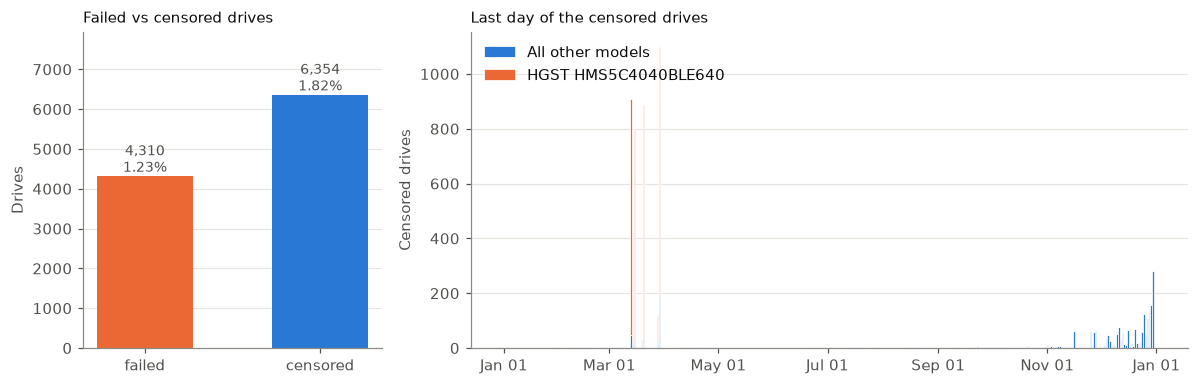

In [12]:
# --- 1. One outcome per drive ---
con.execute(f"""
    CREATE OR REPLACE TABLE drive_outcomes AS
    WITH d AS (
        SELECT serial_number, ARG_MAX(model, date) AS model, MIN(date) AS first_day, MAX(date) AS last_day,
               COUNT(*) AS n_days, SUM(failure) > 0 AS failed
        FROM dq GROUP BY serial_number
    )
    SELECT d.*, m.manufacturer,
           (NOT d.failed AND d.last_day < DATE '{cfg.end_date}') AS censored,
           CASE WHEN d.failed THEN 'failed' WHEN d.last_day < DATE '{cfg.end_date}' THEN 'censored' ELSE 'active' END AS outcome
    FROM d LEFT JOIN model_info m USING (model)
""")
con.execute(f"COPY drive_outcomes TO '{(cfg.cache_dir / 'drive_outcomes.parquet').as_posix()}' (FORMAT PARQUET)")
outcomes = con.execute("SELECT * FROM drive_outcomes").df()
counts = outcomes["outcome"].value_counts()
print(f"Drives: {len(outcomes):,} | " + " | ".join(f"{k}: {counts.get(k, 0):,} ({counts.get(k, 0) / len(outcomes):.2%})"
                                                 for k in ["failed", "censored", "active"]))

# --- 2. How many, and when do they leave? ---
cens = outcomes[outcomes["censored"]].copy()
top_model = cens["model"].value_counts().index[0]
cens["group"] = np.where(cens["model"] == top_model, top_model, "All other models")
per_day = (cens.groupby(["last_day", "group"]).size().unstack(fill_value=0)
           .reindex(pd.date_range(cfg.start_date, cfg.end_date), fill_value=0))
per_day.to_csv(cfg.cache_dir / "censored_drives_by_day.csv")
top_color = MANUF_COLORS.get(manufacturer_of(top_model), OTHER_COLOR)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2.4]})
fc = counts.reindex(["failed", "censored"])
ax1.bar(fc.index, fc.values, color=[ORANGE, BLUE], width=0.55)
for x, v in enumerate(fc.values):
    ax1.text(x, v, f"{v:,}\n{v / len(outcomes):.2%}", ha="center", va="bottom", fontsize=9, color=MUTED)
ax1.set_ylim(0, fc.max() * 1.25)
ax1.set_ylabel("Drives")
ax1.set_title("Failed vs censored drives", loc="left", fontsize=10)
ax1.grid(axis="x", visible=False)

bottom = np.zeros(len(per_day))
for name, color in [("All other models", BLUE), (top_model, top_color)]:
    if name in per_day:
        ax2.bar(per_day.index, per_day[name], bottom=bottom, color=color, width=0.85, label=name,
                edgecolor="white", linewidth=0.5)
        bottom += per_day[name].to_numpy()
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax2.set_ylabel("Censored drives")
ax2.set_title("Last day of the censored drives", loc="left", fontsize=10)
ax2.grid(axis="x", visible=False)
ax2.legend(frameon=False, loc="upper left")
finish(fig, "censored_drives")

**Takeaways.** 6,354 drives (1.82%) are censored, against 4,310 failed (1.23%) and 338,798 active (96.95%). They come from two events:
- 3,930 are HGST HMS5C4040BLE640, which left between 13 and 29 March, as in Q1. This looks like a bulk decommission, and only this model is concerned.
- The other 2,424 leave almost all in November and December, up to 281 on 2025-12-30. This is the period of the fall in failures per day (4.5), so some may be unflagged failures. If so, treating them as censored would hide real failures.

We keep all of them and use the flag. The question must be answered before the labels are built. A returning drive (see 4.6) is counted once, as failed.